# 05b — Death and discharge as competing events

## Summary

Estimate unadjusted admission-level cumulative incidence of in-hospital death and live discharge through day 28. Include age/sex/era cause-specific Cox models with patient-cluster inference. Saved clinical tables and the published figure are displayed separately below. A new runtime execution defaults to current clinical data and stops if required access or configuration is missing.

<!-- Generated notebook input context -->

## Inputs and execution mode

New execution defaults to current clinical data. The input cell announces its mode before loading. Missing configuration, credentials or access stops execution without a synthetic fallback. Choose synthetic explicitly for artificial software checks, or local explicitly for a verified saved aggregate bundle. Existing stored runtime outputs retain their earlier origin labels; changing this policy does not rerun or revalidate them.

Stored-output evidence: [original clinical execution](../docs/NOTEBOOK_EXECUTION_VALIDATION.json) · [presentation refresh](../docs/NOTEBOOK_PRESENTATION_VALIDATION.json). · [current-mode execution](../docs/SUPPLEMENT_NOTEBOOK_EXECUTION_VALIDATION.json).

<!-- Generated saved clinical supplement: competing/intro; edit scripts/render_supplement_notebook_summaries.py -->

## Saved clinical results

The tables and figures in this section display saved clinical execution results from [the public aggregate record](../docs/SURVIVAL_SENSITIVITY_RESULTS.json). They do not represent a new clinical rerun. The separately labeled execution section describes how to reproduce outputs. Any synthetic execution is explicitly labeled and is not a clinical MIMIC result.

<!-- Generated saved clinical supplement: competing/cif; edit scripts/render_supplement_notebook_summaries.py -->

### Table 1 — Saved death and live-discharge cumulative incidence

| Qualifying RAAS orders | Day | Death CIF %, 95% CI | Live-discharge CIF %, 95% CI |
| --- | ---: | --- | --- |
| No | 7 | 8.90 (8.41–9.43) | 43.62 (42.66–44.59) |
| No | 14 | 11.84 (11.26–12.42) | 69.55 (68.68–70.48) |
| No | 28 | 13.90 (13.28–14.54) | 81.68 (80.95–82.40) |
| Yes | 7 | 5.60 (4.15–7.15) | 49.58 (46.34–52.83) |
| Yes | 14 | 8.03 (6.21–9.93) | 77.70 (74.73–80.39) |
| Yes | 28 | 9.09 (7.09–11.08) | 87.95 (85.76–90.06) |

**Summary:** At day 28, unadjusted death CIF is 9.09% with qualifying RAAS orders and 13.90% without; live-discharge CIF is 87.95% and 81.68%, respectively. Intervals use 1,000 patient-cluster bootstrap draws and are pointwise, not simultaneous. These unadjusted associations do not establish treatment effects.

Day-28 death-CIF difference, RAAS minus no RAAS: -4.81 percentage points (95% CI -6.82 to -2.66).

### Figure 1 — Death and live-discharge cumulative incidence

![Figure 1 — Death and live-discharge cumulative incidence](../assets/supplementary_competing_risks.svg)

**How to read**

- The horizontal axis is days since ICU entry. The left panel is the unadjusted cumulative incidence of hospital death and the right panel is live discharge, treating the other endpoint as competing. Blue denotes qualifying RAAS orders; orange denotes no qualifying orders. Each curve's height is an absolute cumulative probability, not a hazard ratio.
- Shading shows pointwise patient-bootstrap 95% intervals on the saved daily grid. These are not simultaneous confidence bands. The published death panel spans 0–20%, while the discharge panel spans 0–100%; compare the printed percentages rather than line heights between panels.

**What the results show**

- At day 28, death CIF is 9.09% with qualifying orders and 13.90% without. Live-discharge CIF is 87.95% and 81.68%, respectively. The saved estimates indicate different observed endpoint patterns between the groups.

**Interpretation limits**

- These curves are unadjusted associations and do not establish a treatment effect. They answer a different question from the adjusted cause-specific HRs and from Kaplan–Meier curves that censor discharge. No Fine–Gray model is shown.

<!-- Generated saved clinical supplement: competing/adjusted; edit scripts/render_supplement_notebook_summaries.py -->

### Table 2 — Saved adjusted cause-specific Cox associations

| Endpoint | HR | Patient-cluster 95% CI | p |
| --- | ---: | --- | ---: |
| In-hospital death | 0.732 | 0.593–0.902 | 0.00346 |
| Live discharge | 1.168 | 1.087–1.254 | 0.00002 |

**Summary:** death: HR 0.732 (95% CI 0.593–0.902); p=0.003455. 11,964 admissions, 1,692 deaths. The interval lies below 1. discharge: HR 1.168 (95% CI 1.087–1.254); p=2.088e-05. 11,964 admissions, 10,272 live discharges. The interval lies above 1.

The age/sex/era cause-specific models describe rates while alive and hospitalized. Their adjusted HRs and the unadjusted CIFs answer different questions. No Fine–Gray model or causal treatment effect is claimed.

## Context & Methods

Code recorded in-hospital death as event 1 and live discharge as event 2, keeping continuous elapsed follow-up. Use the two-cause Aalen-Johansen product integral with a common pre-event risk set for tied death, discharge and censor times. The input hospital episodes have both endpoints observed; no out-of-hospital mortality is added.

### Key assumptions
- CIF curves are unadjusted; adjusted cause-specific hazard ratios answer a different question.
- Resample patients globally with replacement, carrying every admission and exposure group with them. Use 1,000 bootstrap draws for clinical runs (200 for explicitly selected synthetic notebook checks).
- Intervals are pointwise 95% percentile intervals, not simultaneous bands.
- Export only the fixed daily grid 0–28, not individual event times. The current Cox death model remains a cause-specific model; this is no automatic replacement by Fine–Gray.
- Death-time fallbacks retain the original discharge-time proxy; exact death timing is uncertain for those admissions.

## Data

Run from the repository root or `notebooks/` after `uv sync --locked`, using the repository Python 3.12 kernel. New execution defaults to `current` and uses the existing read-only BigQuery loader, a US dry run and the 200 MB cap. Configuration, authentication or permission failures stop with a reason and next step. Select `synthetic` explicitly for artificial software tests, or `local` explicitly to inspect a verified saved aggregate bundle without another query. Pseudonymous keys stay in memory; never print source rows.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "scripts"))
import supplement_notebook_runtime as notebook_runtime
from render_supplement_notebook_summaries import style_competing_figure
%matplotlib inline
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
import notebook_presentation as presentation

## Runtime execution

The selected input origin is displayed once below, and again only if it changes. The default is current clinical data; configuration or access failure stops execution. Synthetic demonstrations and saved local aggregates require explicit selection. Figure 1 above remains the fixed published aggregate snapshot; stored runtime outputs retain their earlier execution labels.

In [2]:
# Current clinical data is the default. Other modes require explicit selection.
# Clear earlier results before loading; a failure must not redisplay a previous run.
import os, json
bundle = None
result = None
DATA_MODE = notebook_runtime.resolve_mode()  # current (default), local, synthetic
LOCAL_RESULT = REPO_ROOT / "reports/local_supplements/sensitivity_run02/aggregate_results.json"
BOOTSTRAP_REPLICATES = 1000 if DATA_MODE == "current" else 200

bundle = notebook_runtime.run_notebook_supplement(
    "competing", repo=REPO_ROOT, mode=DATA_MODE, local_result=LOCAL_RESULT,
    bootstrap_replicates=BOOTSTRAP_REPLICATES)
result = bundle["results"]["competing"]
presentation.display_input_context(bundle, mode=DATA_MODE)
# Retain only the aggregate execution bundle under the ignored run directory.
if os.environ.get("COPD_NOTEBOOK_RUN_DIR"):
    aggregate_output = Path(os.environ["COPD_NOTEBOOK_RUN_DIR"]) / "supplement_bundle.json"
    aggregate_output.parent.mkdir(parents=True, exist_ok=True)
    aggregate_output.write_text(json.dumps(bundle, indent=2, allow_nan=False) + "\n")

Input mode = current | CURRENT clinical data: existing read-only SELECT; US dry run and 200 MB cap. Access/configuration failure stops execution.


### Fixed-time cumulative incidence

In [3]:
presentation.display_table("05b", "cif", presentation.cif_frame(result), presentation.cif_summary(result), bundle=bundle)

Qualifying RAAS orders,Day,"Death CIF %, 95% CI","Live-discharge CIF %, 95% CI"
No,7,8.90 (8.41–9.43),43.62 (42.66–44.59)
No,14,11.84 (11.26–12.42),69.55 (68.68–70.48)
No,28,13.90 (13.28–14.54),81.68 (80.95–82.40)
Yes,7,5.60 (4.15–7.15),49.58 (46.34–52.83)
Yes,14,8.03 (6.21–9.93),77.70 (74.73–80.39)
Yes,28,9.09 (7.09–11.08),87.95 (85.76–90.06)


### Adjusted cause-specific associations

In [4]:
presentation.display_table("05b", "models", presentation.supplement_models_frame(result, cause_specific=True), presentation.supplement_models_summary(result, cause_specific=True), bundle=bundle)

,Model,Admissions,Patients,RAAS HR,Ordinary 95% CI,Patient-cluster 95% CI,Ordinary p,Patient-cluster p
0,death,11964,9157,0.732,0.592–0.904,0.593–0.902,0.003832,0.003455
1,discharge,11964,9157,1.168,1.088–1.253,1.087–1.254,1.571e-05,2.088e-05


### Selected-execution figure

The following shared display call generates the figure number, title and numerical interpretation from this execution's aggregate result.

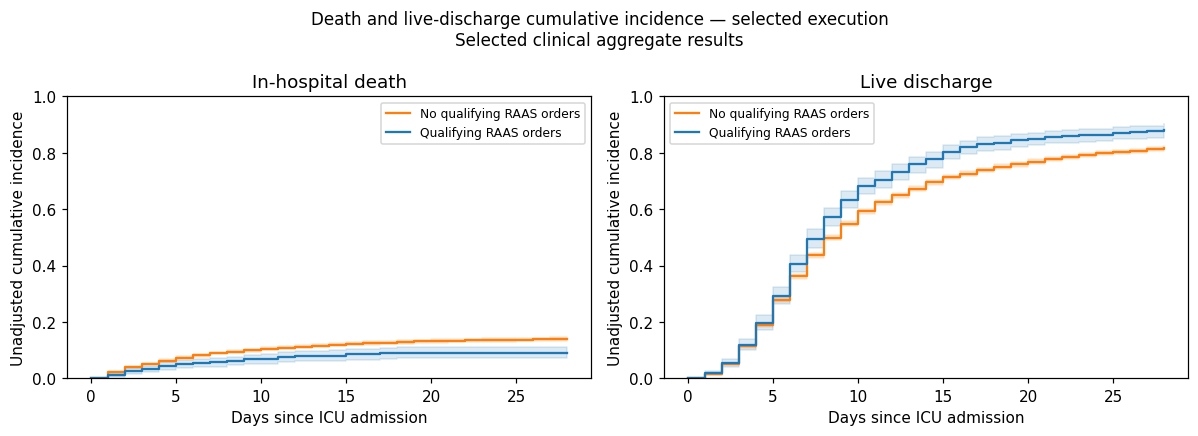

In [5]:
presentation.display_runtime_figure(bundle, "competing")

## Takeaways

Read death and discharge curves together. A cause-specific HR describes the instantaneous rate while still alive and hospitalized; the CIF describes the observed probability of a hospital endpoint by a specified time. The unadjusted CIF difference does not establish a treatment effect. Published Kaplan-Meier curves must not be read as competing-risk-adjusted absolute death probabilities.

See [the supplement guide](../docs/SURVIVAL_SENSITIVITY_SUPPLEMENTS.md) for the execution commands, data handling, reference checks and limitations. Historical [execution](../docs/NOTEBOOK_EXECUTION_VALIDATION.json) and [presentation](../docs/NOTEBOOK_PRESENTATION_VALIDATION.json) evidence is kept separately from this input-policy source change. Publishing changed sources or new runtime outputs requires a matching reviewed validation record. Full local result bundles stay under ignored `reports/local_supplements/`.